## 1. Load the saved portfolio

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RUN_ID = None  # Set explicitly if more than one saved search exists.
base = ROOT / 'outputs' / 'joint_grid_search_zero_cost'
runs = sorted(p.parent for p in base.glob('*/grid_summary.csv'))
if RUN_ID is None:
    if len(runs) != 1:
        raise ValueError(f'Set RUN_ID to one of {[p.name for p in runs]}')
    run = runs[0]
else:
    run = base / RUN_ID
summary = pd.read_csv(run / 'grid_summary.csv')
complete = summary.loc[summary['Status'].eq('complete') & np.isfinite(summary['Sharpe Ratio'])]
if complete.empty:
    raise ValueError('No completed strategy with finite Sharpe ratio.')
winner = complete.sort_values('Sharpe Ratio', ascending=False, kind='stable').iloc[0]
folder = run / Path(winner['Output Folder']).name
params = json.loads((folder / 'parameters.json').read_text())
assert params['cost_bps_per_leg'] == 0
initial = params['initial_capital']
print(f'Run: {run.name}; completed combinations: {len(complete)} / {len(summary)}')
print('Selected parameters:', params)
portfolio = pd.read_csv(folder / 'portfolio_daily.csv', parse_dates=['Date']).set_index('Date').sort_index()
trades = pd.read_csv(folder / 'trades.csv')
for col in ['Entry Signal Date', 'Entry Date', 'Exit Signal Date', 'Exit Date']:
    trades[col] = pd.to_datetime(trades[col])
assert portfolio.index.is_unique and portfolio.index.max() < pd.Timestamp('2023-08-25')
assert trades[['Entry Date', 'Exit Date']].notna().all().all()
assert trades['Exit Date'].ge(trades['Entry Date']).all()
trades['Entry Year'] = trades['Entry Date'].dt.year
trades['Exit Year'] = trades['Exit Date'].dt.year
trades['Pair'] = [' / '.join(sorted((a, b))) for a, b in zip(trades.A, trades.B)]
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
BLUE, GREEN, RED = '#2878a5', '#559b87', '#c55151'

figures = []


Run: cb64c19613e1e11beb71; completed combinations: 1248 / 1248
Selected parameters: {'formation_months': 18, 'trading_months': 6, 'correlation_threshold': 0.8, 'eg_significance': 0.01, 'entry_z': 1.5, 'exit_z': 0.5, 'stop_z': 4.0, 'run_id': 'cb64c19613e1e11beb71', 'cost_bps_per_leg': 0.0, 'initial_capital': 100000.0}


## 2. Portfolio performance

Cumulative return compounds daily portfolio returns across the full backtest, including open positions. The trailing 252-session return compounds only the most recent 252 trading sessions; it starts after a full window is available. Drawdown shows losses from previous peaks.


,Saved portfolio
Total return,18.61%
Maximum drawdown,-3.50%
Completed trades,212
Trade win rate,63.2%
Median holding sessions,19


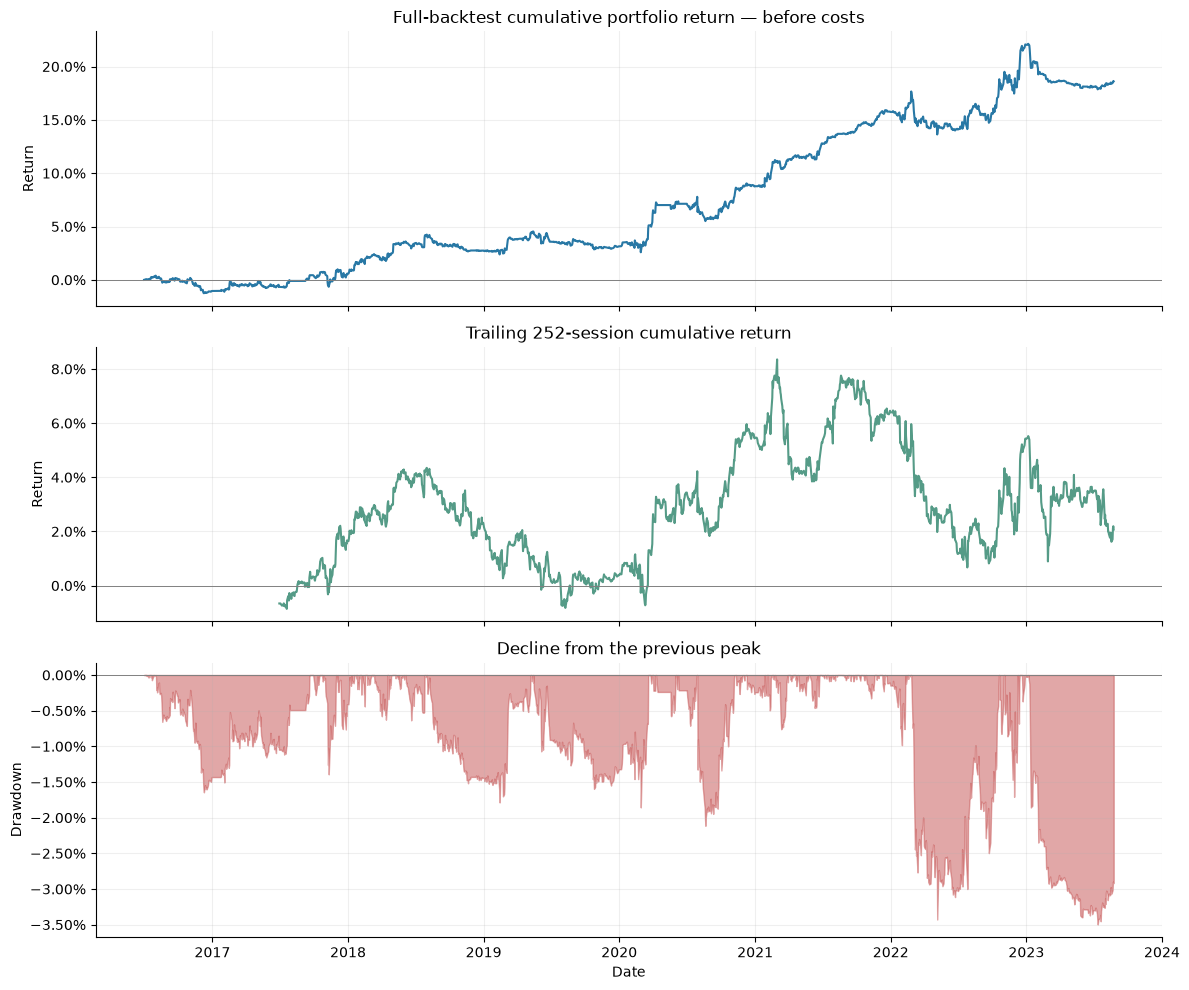

2016-07-01 to 2023-08-24 | 1,799 sessions


In [2]:
portfolio_cumulative_return = (1 + portfolio['Net Return']).cumprod() - 1
np.testing.assert_allclose(portfolio_cumulative_return, portfolio['Equity'] / initial - 1, atol=1e-10)
np.testing.assert_allclose(portfolio_cumulative_return.iloc[-1], winner['Cumulative Return'], atol=1e-10)
# Include starting capital in the peak so an initial loss counts as a drawdown.
drawdown = portfolio['Equity'] / portfolio['Equity'].cummax().clip(lower=initial) - 1
metrics = pd.Series({
    'Total return': f'{portfolio_cumulative_return.iloc[-1]:.2%}',
    'Maximum drawdown': f'{drawdown.min():.2%}',
    'Completed trades': f'{len(trades):,}',
    'Trade win rate': f"{trades['Net P/L ($)'].gt(0).mean():.1%}",
    'Median holding sessions': f"{trades['Holding Sessions'].median():.0f}",
}, name='Saved portfolio')
display(metrics.to_frame())
rolling_return = (1 + portfolio['Net Return']).rolling(252, min_periods=252).apply(np.prod, raw=True) - 1
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axes[0].plot(portfolio.index, portfolio_cumulative_return, color=BLUE)
axes[0].set(title='Full-backtest cumulative portfolio return — before costs', ylabel='Return')
axes[1].plot(portfolio.index, rolling_return, color=GREEN)
axes[1].set(title='Trailing 252-session cumulative return', ylabel='Return')
axes[2].fill_between(portfolio.index, drawdown, 0, color=RED, alpha=0.5)
axes[2].set(title='Decline from the previous peak', ylabel='Drawdown', xlabel='Date')
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.axhline(0, color='gray', linewidth=0.7)
fig.tight_layout()
figures.append(fig)
plt.show()
print(f'{portfolio.index.min():%Y-%m-%d} to {portfolio.index.max():%Y-%m-%d} | {len(portfolio):,} sessions')

### Was performance consistent across years?

Portfolio returns include open positions. Trades are counted when they close. The first and last years may be partial.

In [3]:
annual = portfolio.groupby(portfolio.index.year).agg(
    Start=('Equity', lambda s: s.index.min()), End=('Equity', lambda s: s.index.max()),
    Sessions=('Equity', 'size'), Closing_equity=('Equity', 'last'))
annual.index.name = 'Year'
annual['Opening equity ($)'] = annual['Closing_equity'].shift().fillna(initial)
annual['Return'] = (1 + portfolio['Net Return']).groupby(portfolio.index.year).prod() - 1
annual['Portfolio P&L ($)'] = annual['Closing_equity'] - annual['Opening equity ($)']
annual['Entries'] = trades.groupby('Entry Year').size().reindex(annual.index, fill_value=0)
annual['Completed trades'] = trades.groupby('Exit Year').size().reindex(annual.index, fill_value=0)
annual['Realized trade P&L ($)'] = trades.groupby('Exit Year')['Net P/L ($)'].sum().reindex(annual.index, fill_value=0)
annual['Win rate'] = trades.groupby('Exit Year')['Net P/L ($)'].agg(lambda x: x.gt(0).mean()).reindex(annual.index)
annual['Median holding sessions'] = trades.groupby('Exit Year')['Holding Sessions'].median().reindex(annual.index)
annual['Partial year'] = (annual['Start'].dt.month.ne(1) | annual['End'].dt.month.ne(12))
np.testing.assert_allclose((1 + annual['Return']).prod() - 1, winner['Cumulative Return'], atol=1e-10)
np.testing.assert_allclose(annual['Return'], annual['Closing_equity'] / annual['Opening equity ($)'] - 1, atol=1e-10)
np.testing.assert_allclose(trades['Net P/L ($)'].sum(), portfolio['Equity'].iloc[-1] - initial, atol=1e-6)
assert annual['Completed trades'].sum() == len(trades) == int(winner['Number of Trades'])
display(annual[['Return', 'Portfolio P&L ($)', 'Completed trades', 'Win rate', 'Partial year']].style.format({'Return': '{:.2%}', 'Portfolio P&L ($)': '${:,.2f}', 'Win rate': '{:.1%}'}))

,Return,Portfolio P&L ($),Completed trades,Win rate,Partial year
Year,,,,,
2016,-1.04%,"$-1,044.68",29,48.3%,True
2017,1.64%,"$1,619.77",18,66.7%,False
2018,2.15%,"$2,163.60",34,55.9%,False
2019,0.40%,$405.99,24,62.5%,False
2020,5.46%,"$5,633.88",30,70.0%,False
2021,6.40%,"$6,961.36",42,78.6%,False
2022,5.45%,"$6,302.17",21,71.4%,False
2023,-2.81%,"$-3,433.72",14,35.7%,True


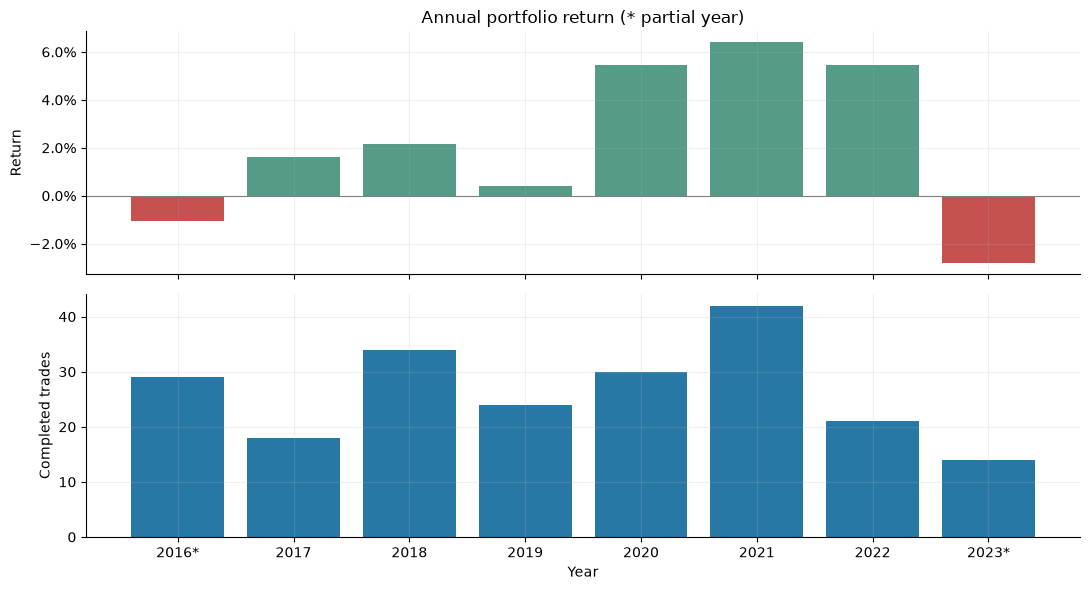

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
labels = [f"{year}{'*' if partial else ''}" for year, partial in annual['Partial year'].items()]
axes[0].bar(labels, annual['Return'], color=np.where(annual['Return'].ge(0), GREEN, RED))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].axhline(0, color='gray', linewidth=0.8)
axes[0].set(title='Annual portfolio return (* partial year)', ylabel='Return')
axes[1].bar(labels, annual['Completed trades'], color=BLUE)
axes[1].set(ylabel='Completed trades', xlabel='Year')
fig.tight_layout()
figures.append(fig)
plt.show()

### When did gains and losses cluster?

Monthly returns compound daily portfolio returns. Blank months fall outside the backtest; the first and last observed months may be partial.


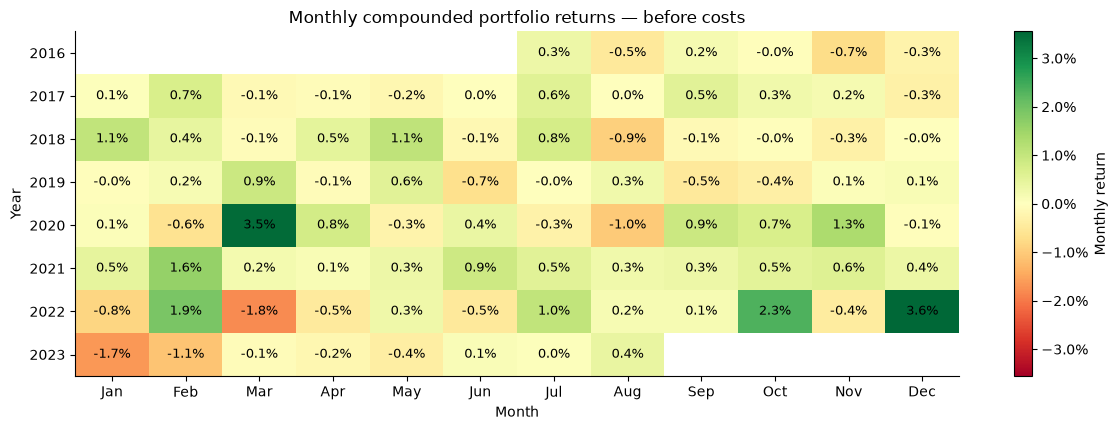

In [5]:
monthly_returns = (1 + portfolio['Net Return']).groupby(portfolio.index.to_period('M')).prod() - 1
np.testing.assert_allclose((1 + monthly_returns).prod() - 1, portfolio_cumulative_return.iloc[-1], atol=1e-10)
monthly_grid = pd.DataFrame({'Year': monthly_returns.index.year, 'Month': monthly_returns.index.month,
                             'Return': monthly_returns.to_numpy()}).pivot(index='Year', columns='Month', values='Return')
monthly_grid = monthly_grid.reindex(columns=range(1, 13))
limit = max(float(monthly_returns.abs().max()), 1e-6)
fig, ax = plt.subplots(figsize=(12, max(4, len(monthly_grid) * 0.55)))
heatmap = ax.imshow(np.ma.masked_invalid(monthly_grid.to_numpy()), cmap='RdYlGn',
                    vmin=-limit, vmax=limit, aspect='auto')
ax.set(xticks=range(12), xticklabels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                                    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
       yticks=range(len(monthly_grid)), yticklabels=monthly_grid.index,
       title='Monthly compounded portfolio returns — before costs', xlabel='Month', ylabel='Year')
ax.grid(False)
for row in range(len(monthly_grid)):
    for col in range(12):
        value = monthly_grid.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f'{value:.1%}', ha='center', va='center', fontsize=9)
fig.colorbar(heatmap, ax=ax, format=PercentFormatter(1), label='Monthly return')
fig.tight_layout()
figures.append(fig)
plt.show()


## 3. Trade outcomes

Compare the typical trade with the large winners and losers. Dollar profit reflects both trade performance and allocation size.

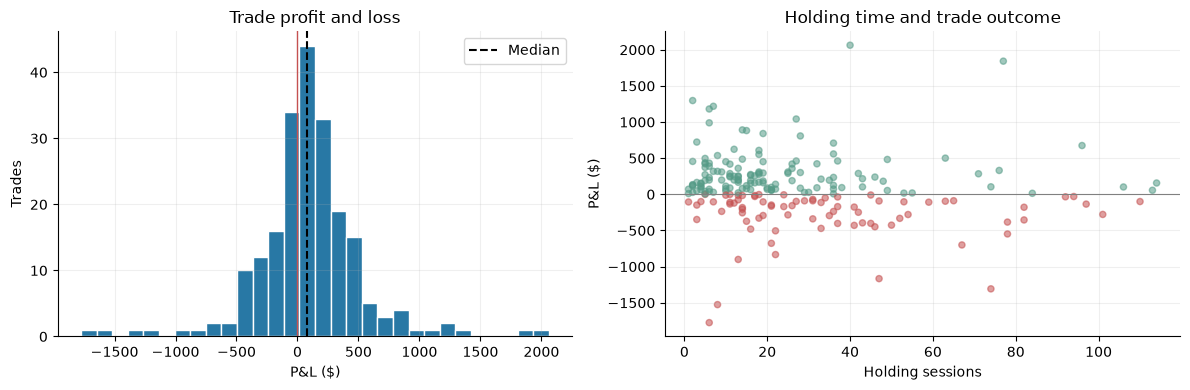

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(trades['Net P/L ($)'], bins=30, color=BLUE, edgecolor='white')
axes[0].axvline(0, color=RED, linewidth=1)
axes[0].axvline(trades['Net P/L ($)'].median(), color='black', linestyle='--', label='Median')
axes[0].set(title='Trade profit and loss', xlabel='P&L ($)', ylabel='Trades')
axes[0].legend()
axes[1].scatter(trades['Holding Sessions'], trades['Net P/L ($)'],
                c=np.where(trades['Net P/L ($)'].ge(0), GREEN, RED), alpha=0.55, s=20)
axes[1].axhline(0, color='gray', linewidth=0.8)
axes[1].set(title='Holding time and trade outcome', xlabel='Holding sessions', ylabel='P&L ($)')
fig.tight_layout()
figures.append(fig)
plt.show()

### How did losing trades close?

Compare the number of losing trades and the dollars lost by exit reason. An exit reason describes how a trade closed; it does not establish the cause of the loss.

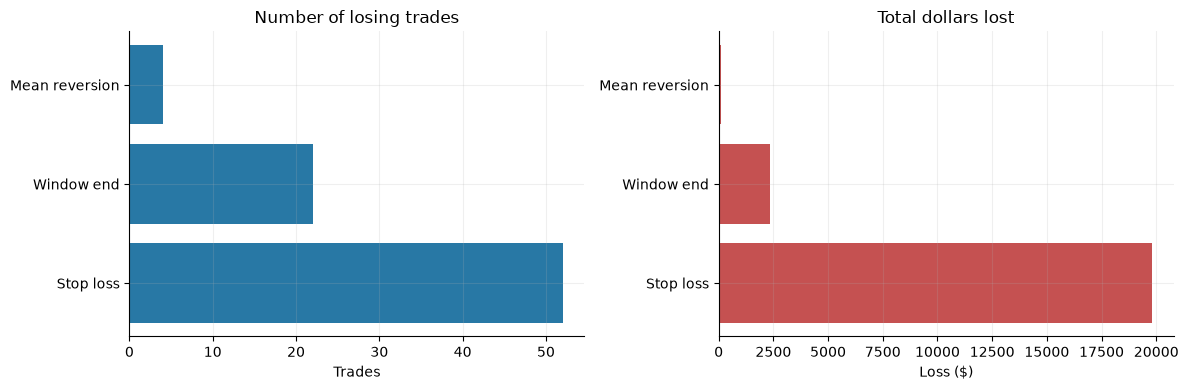

,Loss ($),Share of total losses (%),Portfolio return contribution (pp)
Exit reason,,,
Stop loss,"$19,799.09",89.0%,-19.80
Window end,"$2,338.98",10.5%,-2.34
Mean reversion,$115.40,0.5%,-0.12


In [7]:
import matplotlib.pyplot as plt

losing_trades = trades.loc[trades['Net P/L ($)'].lt(0)].copy()
exit_names = {'Stop loss': 'Stop loss', 'End of window': 'Window end', 'Mean reversion': 'Mean reversion'}
assert losing_trades['Exit Reason'].isin(exit_names).all(), 'Unexpected or missing exit reason'
losing_exit_counts = losing_trades['Exit Reason'].value_counts().reindex(exit_names, fill_value=0)
assert losing_exit_counts.sum() == len(losing_trades)
losing_exit_summary = losing_exit_counts.rename('Losing trades').to_frame()
losing_exit_summary.index = losing_exit_summary.index.map(exit_names)
losing_exit_summary['Share (%)'] = losing_exit_summary['Losing trades'] / len(losing_trades) * 100 if len(losing_trades) else 0.0
losing_exit_summary.index.name = 'Exit reason'


loss_by_exit = (-losing_trades.groupby('Exit Reason')['Net P/L ($)'].sum()).reindex(exit_names, fill_value=0.0)
total_losses = loss_by_exit.sum()
np.testing.assert_allclose(total_losses, -losing_trades['Net P/L ($)'].sum(), atol=1e-6)
loss_exit_summary = loss_by_exit.rename('Loss ($)').to_frame()
loss_exit_summary.index = loss_exit_summary.index.map(exit_names)
loss_exit_summary.index.name = 'Exit reason'
loss_exit_summary['Share of total losses (%)'] = loss_exit_summary['Loss ($)'] / total_losses * 100 if total_losses > 0 else 0.0
loss_exit_summary['Portfolio return contribution (pp)'] = -loss_exit_summary['Loss ($)'] / initial * 100


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(losing_exit_summary.index, losing_exit_summary['Losing trades'], color=BLUE)
axes[0].set(title='Number of losing trades', xlabel='Trades')
axes[1].barh(loss_exit_summary.index, loss_exit_summary['Loss ($)'], color=RED)
axes[1].set(title='Total dollars lost', xlabel='Loss ($)')
fig.tight_layout()
figures.append(fig)
plt.show()
display(loss_exit_summary.style.format({'Loss ($)': '${:,.2f}',
    'Share of total losses (%)': '{:.1f}%', 'Portfolio return contribution (pp)': '{:+.2f}'}))


## 4. Pair contributions

Add up each pair’s dollar profit across trading windows. Larger allocations can produce larger contributions. This is not a backtest of each pair on its own.

In [8]:
# Reconstruct daily dollar contributions with the engine's allocation at each window start.
keys = ['Window', 'A', 'B']
pair_daily = pd.read_csv(folder / 'pair_daily.csv.gz', parse_dates=['Date'])
selected_pairs = pd.read_csv(folder / 'selected_pairs.csv')
window_summary = pd.read_csv(folder / 'window_summary.csv')
allocation = window_summary.set_index('Window')['Initial Capital'] / selected_pairs.groupby('Window').size()
pair_daily = pair_daily.sort_values(keys + ['Date'])
prior = pair_daily.groupby(keys)['Equity'].shift().fillna(pair_daily['Window'].map(allocation))
pair_daily['Daily P&L ($)'] = pair_daily['Equity'] - prior
pair_daily['Pair'] = [' / '.join(sorted((a, b))) for a, b in zip(pair_daily.A, pair_daily.B)]
pair_daily['Year'] = pair_daily['Date'].dt.year
attribution_trades = trades.copy()
attribution_trades['Pair'] = [' / '.join(sorted((a, b))) for a, b in zip(trades.A, trades.B)]
pair_year_pnl = pair_daily.pivot_table(index='Pair', columns='Year', values='Daily P&L ($)', aggfunc='sum', fill_value=0).reindex(columns=annual.index, fill_value=0)
pair_contribution = pair_year_pnl.sum(axis=1).to_frame('P&L ($)')
pair_contribution['Contribution (pp)'] = pair_contribution['P&L ($)'] / initial * 100
trade_stats = attribution_trades.groupby('Pair').agg(
    Trades=('Net P/L ($)', 'size'), Win_rate=('Net P/L ($)', lambda s: s.gt(0).mean()),
    Realized_PnL=('Net P/L ($)', 'sum'), Median_holding_sessions=('Holding Sessions', 'median'))
pair_contribution = pair_contribution.join(trade_stats)
pair_contribution['Trades'] = pair_contribution['Trades'].fillna(0).astype(int)
pair_contribution['Realized_PnL'] = pair_contribution['Realized_PnL'].fillna(0)
pair_contribution['Selected windows'] = pair_daily.groupby('Pair')['Window'].nunique()
pair_contribution = pair_contribution.sort_values('P&L ($)', ascending=False)
np.testing.assert_allclose(pair_year_pnl.sum(axis=0), annual['Portfolio P&L ($)'], atol=1e-6)
np.testing.assert_allclose(pair_contribution['P&L ($)'], pair_contribution['Realized_PnL'], atol=1e-6)
np.testing.assert_allclose(pair_contribution['Contribution (pp)'].sum(), winner['Cumulative Return'] * 100, atol=1e-8)
assert pair_contribution['Trades'].sum() == len(trades)
print('Pair contributions reconcile to annual portfolio P&L, realized trades, and total return.')
display(pair_contribution[['P&L ($)', 'Trades', 'Selected windows']].head(10).round(2))

Pair contributions reconcile to annual portfolio P&L, realized trades, and total return.


,P&L ($),Trades,Selected windows
Pair,,,
MCO / SPGI,4129.11,5,1
MLM / VMC,2120.12,8,2
LUV / UAL,1961.61,4,2
ALK / DAL,1842.42,1,1
QRVO / SWKS,1503.45,2,1
AEP / ED,1314.70,7,2
AFL / L,1202.17,3,1
AWK / NEE,939.50,3,1
HST / KIM,882.08,1,1


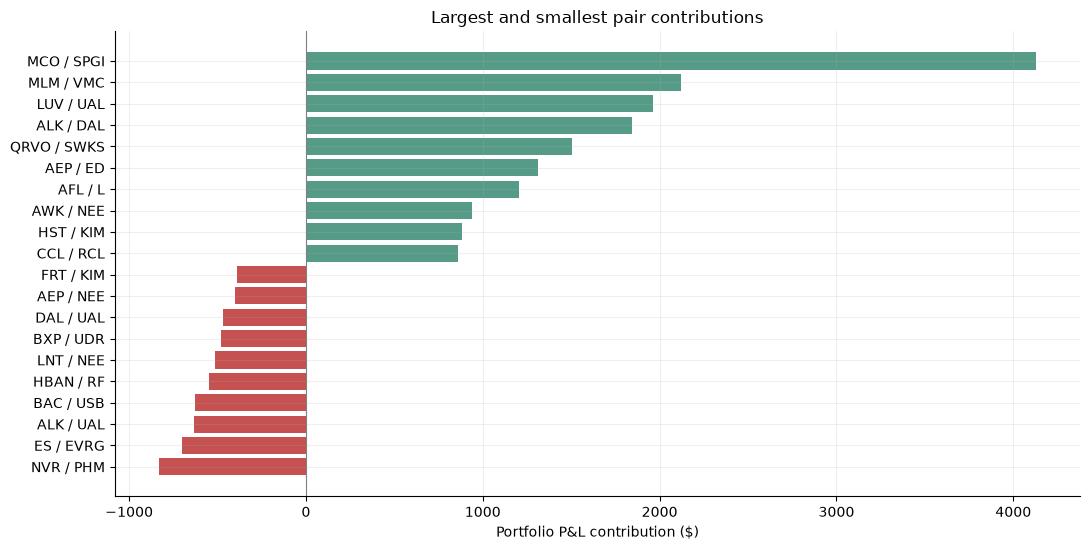

In [9]:
# Show both ends of the ranking without counting a pair twice.
ranked = pd.concat([pair_contribution.head(10), pair_contribution.tail(10)])
ranked = ranked.loc[~ranked.index.duplicated()].sort_values('P&L ($)')
fig, ax = plt.subplots(figsize=(11, max(4, len(ranked) * 0.28)))
ax.barh(ranked.index, ranked['P&L ($)'], color=np.where(ranked['P&L ($)'].ge(0), GREEN, RED))
ax.axvline(0, color='gray', linewidth=0.8)
ax.set(title='Largest and smallest pair contributions', xlabel='Portfolio P&L contribution ($)')
fig.tight_layout()
figures.append(fig)
plt.show()

### How much depends on the biggest winners?

Subtract the best 1, 5, and 10 profitable trades or pairs from recorded profit. Other trades and allocations stay fixed: this is a sensitivity check, not a new backtest. Shares of net profit can exceed 100% because losses offset winners.

In [10]:
total_profit = trades['Net P/L ($)'].sum()
rows = []
for unit, profits in [('Trades', trades['Net P/L ($)']), ('Pairs', pair_contribution['P&L ($)'])]:
    winners = profits[profits > 0].sort_values(ascending=False)
    gross_wins = winners.sum()
    for k in [1, 5, 10]:
        removed = winners.head(k).sum()
        remaining = total_profit - removed
        rows.append({'Remove best': unit, 'Number removed': min(k, len(winners)),
                     'Removed profit ($)': removed,
                     'Share of all positive profits': removed / gross_wins if gross_wins else np.nan,
                     'Share of net portfolio profit': removed / total_profit if total_profit > 0 else np.nan,
                     'Remaining profit ($)': remaining,
                     'Remaining profit / initial capital': remaining / initial})
concentration = pd.DataFrame(rows)
np.testing.assert_allclose(total_profit, pair_contribution['P&L ($)'].sum(), atol=1e-6)
np.testing.assert_allclose(concentration['Removed profit ($)'] + concentration['Remaining profit ($)'], total_profit, atol=1e-6)
display(concentration.style.format({'Removed profit ($)': '${:,.2f}', 'Share of all positive profits': '{:.1%}',
    'Share of net portfolio profit': '{:.1%}', 'Remaining profit ($)': '${:,.2f}',
    'Remaining profit / initial capital': '{:.2%}'}))
print('Ten most profitable trades (actual dollar contributions):')
display(trades.sort_values('Net P/L ($)', ascending=False)[['Pair', 'Entry Date', 'Exit Date', 'Net P/L ($)', 'Exit Reason']].head(10).round(2))

,Remove best,Number removed,Removed profit ($),Share of all positive profits,Share of net portfolio profit,Remaining profit ($),Remaining profit / initial capital
0,Trades,1,"$2,062.95",5.0%,11.1%,"$16,545.41",16.55%
1,Trades,5,"$7,601.37",18.6%,40.8%,"$11,006.98",11.01%
2,Trades,10,"$12,247.22",30.0%,65.8%,"$6,361.13",6.36%
3,Pairs,1,"$4,129.11",13.2%,22.2%,"$14,479.24",14.48%
4,Pairs,5,"$11,556.71",37.0%,62.1%,"$7,051.64",7.05%
5,Pairs,10,"$16,756.08",53.7%,90.0%,"$1,852.27",1.85%


Ten most profitable trades (actual dollar contributions):


/tmp/ipykernel_3847488/3217727142.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(trades.sort_values('Net P/L ($)', ascending=False)[['Pair', 'Entry Date', 'Exit Date', 'Net P/L ($)', 'Exit Reason']].head(10).round(2))


,Pair,Entry Date,Exit Date,Net P/L ($),Exit Reason
196,LUV / UAL,2022-10-20,2022-12-16,2062.95,Mean reversion
190,ALK / DAL,2022-07-01,2022-10-20,1842.42,Mean reversion
110,MCO / SPGI,2020-03-18,2020-03-20,1297.33,Mean reversion
195,LUV / UAL,2022-07-22,2022-08-02,1217.91,Mean reversion
111,MCO / SPGI,2020-03-25,2020-04-02,1180.76,Mean reversion
193,QRVO / SWKS,2022-09-01,2022-10-11,1042.05,Mean reversion
62,MLM / VMC,2018-04-26,2018-05-04,989.24,Mean reversion
185,ALK / UAL,2022-01-21,2022-02-10,891.32,Mean reversion
140,HST / KIM,2021-01-26,2021-02-17,882.08,Mean reversion
88,CFG / PNC,2019-02-08,2019-03-08,841.16,Mean reversion


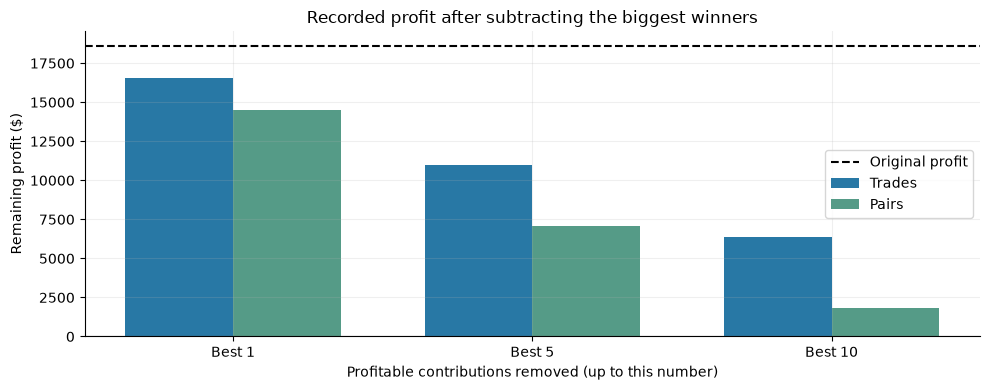

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for offset, unit, color in [(-0.18, 'Trades', BLUE), (0.18, 'Pairs', GREEN)]:
    values = concentration.loc[concentration['Remove best'].eq(unit), 'Remaining profit ($)']
    ax.bar(np.arange(3) + offset, values, width=0.36, label=unit, color=color)
ax.axhline(total_profit, color='black', linestyle='--', label='Original profit')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set(xticks=np.arange(3), xticklabels=['Best 1', 'Best 5', 'Best 10'],
       xlabel='Profitable contributions removed (up to this number)', ylabel='Remaining profit ($)',
       title='Recorded profit after subtracting the biggest winners')
ax.legend()
fig.tight_layout()
figures.append(fig)
plt.show()

## 5. Stock exposure and overlap

A stock can appear in several active pairs. Same-direction holdings reinforce exposure; opposing holdings partly offset it. We inspect positions after each close, so intraday overlap is not measured.

In [12]:
# One row per active pair leg. Prices use the same adjusted scale as saved units.
legs = []
for leg in ['A', 'B']:
    part = pair_daily[['Date', 'Window', 'A', 'B', f'Units {leg}']].copy()
    part['Stock'] = part[leg]
    part = part.rename(columns={f'Units {leg}': 'Units'})
    part = part.loc[part['Units'].ne(0)]
    part['Pair'] = [' / '.join(sorted((a, b))) for a, b in zip(part.A, part.B)]
    legs.append(part[['Date', 'Window', 'Pair', 'Stock', 'Units']])
stock_legs = pd.concat(legs, ignore_index=True)
assert not stock_legs.duplicated(['Date', 'Window', 'Pair', 'Stock']).any()
price_parts = []
for ticker in sorted(stock_legs['Stock'].unique()):
    bars = pd.read_csv(ROOT / 'data/historical' / f'{ticker}.csv', usecols=['Date', 'Adj Close'])
    bars['Date'] = pd.to_datetime(bars['Date'])
    bars = bars.loc[bars['Date'].isin(portfolio.index)].copy()
    assert not bars['Date'].duplicated().any()
    bars['Adj Close'] = pd.to_numeric(bars['Adj Close'], errors='coerce')
    bars['Stock'] = ticker
    price_parts.append(bars)
stock_prices = pd.concat(price_parts, ignore_index=True) if price_parts else pd.DataFrame(columns=['Date', 'Adj Close', 'Stock'])
stock_legs = stock_legs.merge(stock_prices, on=['Date', 'Stock'], how='left', validate='many_to_one')
assert (np.isfinite(stock_legs['Adj Close']) & stock_legs['Adj Close'].gt(0)).all()
stock_legs['Exposure ($)'] = stock_legs['Units'] * stock_legs['Adj Close']
stock_legs['Long'] = stock_legs['Units'].gt(0).astype(int)
stock_legs['Short'] = stock_legs['Units'].lt(0).astype(int)
stock_exposure = stock_legs.groupby(['Date', 'Stock']).agg(
    Pairs=('Pair', 'nunique'), Long_pairs=('Long', 'sum'), Short_pairs=('Short', 'sum'),
    Net_exposure_dollars=('Exposure ($)', 'sum'),
    Gross_exposure_dollars=('Exposure ($)', lambda x: x.abs().sum()),
    Pair_names=('Pair', lambda x: ', '.join(sorted(x)))).reset_index()
stock_exposure['Same direction overlap'] = stock_exposure['Long_pairs'].ge(2) | stock_exposure['Short_pairs'].ge(2)
stock_exposure['Opposite directions'] = stock_exposure['Long_pairs'].gt(0) & stock_exposure['Short_pairs'].gt(0)
stock_exposure['Portfolio equity ($)'] = stock_exposure['Date'].map(portfolio['Equity'])
stock_exposure['Net exposure / equity (%)'] = stock_exposure['Net_exposure_dollars'] / stock_exposure['Portfolio equity ($)'] * 100
stock_exposure['Gross exposure / equity (%)'] = stock_exposure['Gross_exposure_dollars'] / stock_exposure['Portfolio equity ($)'] * 100
assert (stock_exposure['Pairs'] == stock_exposure['Long_pairs'] + stock_exposure['Short_pairs']).all()
assert (stock_exposure['Gross_exposure_dollars'] + 1e-7 >= stock_exposure['Net_exposure_dollars'].abs()).all()
# Verify that leg reconstruction includes every saved nonzero holding.
np.testing.assert_allclose(stock_exposure.groupby('Date')['Gross_exposure_dollars'].sum(),
                           stock_legs.assign(absolute=stock_legs['Exposure ($)'].abs()).groupby('Date')['absolute'].sum())
overlapping_stocks = stock_exposure.loc[stock_exposure['Pairs'].ge(2)].copy()
same_direction = overlapping_stocks.loc[overlapping_stocks['Same direction overlap']].copy()
count_days = len(portfolio)
print(f'Any stock overlap: {overlapping_stocks.Date.nunique()} / {count_days} trading days '
      f'({overlapping_stocks.Date.nunique() / count_days:.1%}).')
print(f'Same-direction overlap: {same_direction.Date.nunique()} / {count_days} trading days '
      f'({same_direction.Date.nunique() / count_days:.1%}), involving {same_direction.Stock.nunique()} different stocks.')
if overlapping_stocks.empty:
    print('No simultaneous stock holdings across multiple pairs were found.')
else:
    print(f'Maximum number of pairs holding one stock at once: {int(overlapping_stocks.Pairs.max())}.')
    largest = same_direction.assign(_rank=same_direction['Net exposure / equity (%)'].abs()).sort_values('_rank', ascending=False)
    if not largest.empty:
        peak = largest.iloc[0]
        print(f"Largest absolute net exposure with same-direction overlap: {peak['Stock']} on {peak['Date']:%Y-%m-%d}, "
              f"{peak['Net exposure / equity (%)']:+.2f}% of equity, held in {int(peak.Pairs)} pairs.")
        display(largest[['Date', 'Stock', 'Pairs', 'Long_pairs', 'Short_pairs',
                         'Net_exposure_dollars', 'Net exposure / equity (%)',
                         'Gross exposure / equity (%)', 'Pair_names']].head(20).round(2))
    else:
        print('The overlaps only involve opposing positions; no same-direction overlaps were found.')


Any stock overlap: 517 / 1799 trading days (28.7%).
Same-direction overlap: 507 / 1799 trading days (28.2%), involving 19 different stocks.
Maximum number of pairs holding one stock at once: 5.
Largest absolute net exposure with same-direction overlap: ETR on 2017-02-16, +25.44% of equity, held in 3 pairs.


/tmp/ipykernel_3847488/1388361076.py:60: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  'Gross exposure / equity (%)', 'Pair_names']].head(20).round(2))


,Date,Stock,Pairs,Long_pairs,Short_pairs,Net_exposure_dollars,Net exposure / equity (%),Gross exposure / equity (%),Pair_names
1563,2017-02-16,ETR,3,3,0,25352.41,25.44,25.44,"AEP / ETR, ES / ETR, ETR / WEC"
1545,2017-02-13,ETR,3,3,0,25070.21,25.26,25.26,"AEP / ETR, ES / ETR, ETR / WEC"
1539,2017-02-10,ETR,3,3,0,24955.24,25.17,25.17,"AEP / ETR, ES / ETR, ETR / WEC"
1527,2017-02-08,ETR,3,3,0,24875.11,25.10,25.10,"AEP / ETR, ES / ETR, ETR / WEC"
1533,2017-02-09,ETR,3,3,0,24735.75,24.96,24.96,"AEP / ETR, ES / ETR, ETR / WEC"
1551,2017-02-14,ETR,3,3,0,24662.58,24.89,24.89,"AEP / ETR, ES / ETR, ETR / WEC"
1512,2017-02-06,ETR,3,3,0,24666.07,24.88,24.88,"AEP / ETR, ES / ETR, ETR / WEC"
1557,2017-02-15,ETR,3,3,0,24655.62,24.87,24.87,"AEP / ETR, ES / ETR, ETR / WEC"
1520,2017-02-07,ETR,3,3,0,24624.27,24.85,24.85,"AEP / ETR, ES / ETR, ETR / WEC"
1251,2016-12-01,USB,5,0,5,-20261.55,-20.46,20.46,"FITB / USB, KEY / USB, MTB / USB, RF / USB, US..."


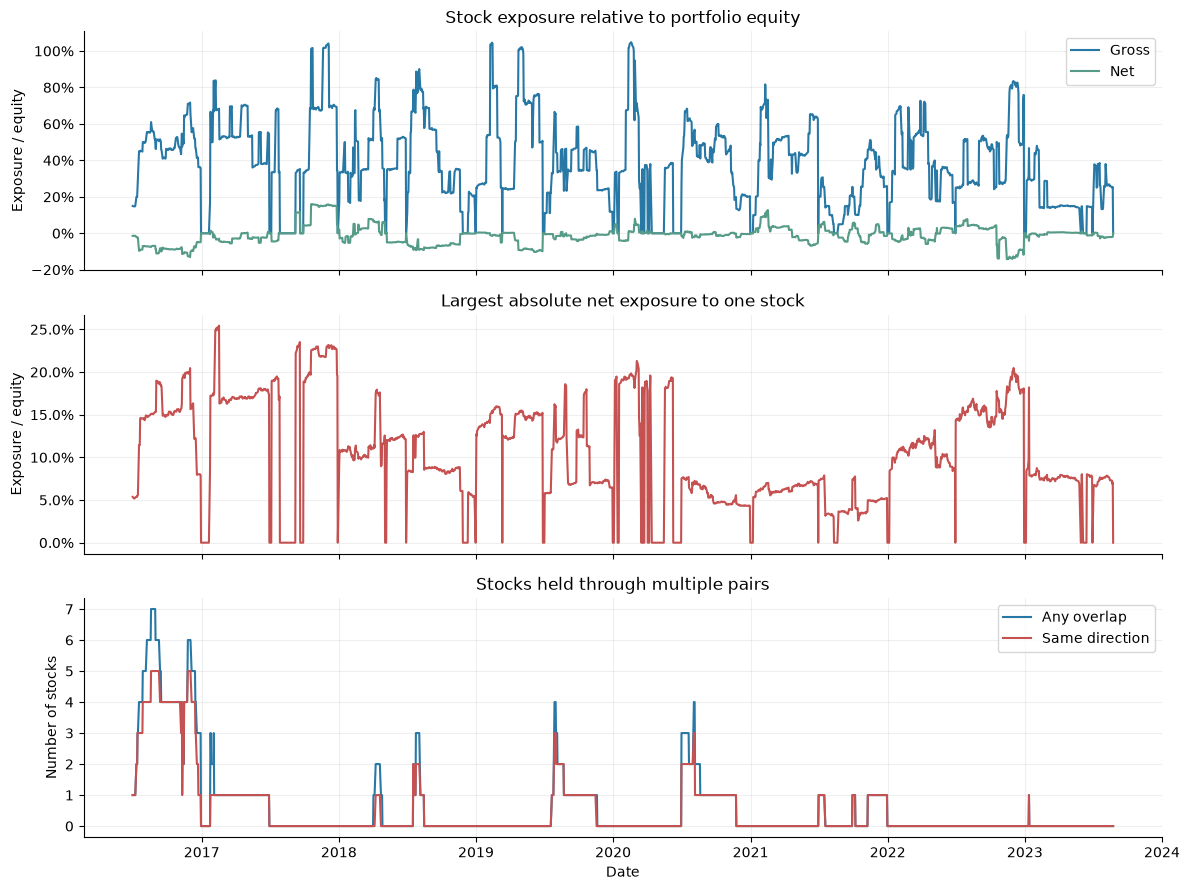

In [13]:
daily_exposure = stock_exposure.groupby('Date').agg(
    gross=('Gross_exposure_dollars', 'sum'), net=('Net_exposure_dollars', 'sum'),
    largest_stock=('Net_exposure_dollars', lambda s: s.abs().max()))
daily_exposure = daily_exposure.reindex(portfolio.index, fill_value=0)
daily_exposure = daily_exposure.div(portfolio['Equity'], axis=0)
overlap_counts = overlapping_stocks.groupby('Date')['Stock'].nunique().reindex(portfolio.index, fill_value=0)
same_counts = same_direction.groupby('Date')['Stock'].nunique().reindex(portfolio.index, fill_value=0)
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(daily_exposure.index, daily_exposure['gross'], label='Gross', color=BLUE)
axes[0].plot(daily_exposure.index, daily_exposure['net'], label='Net', color=GREEN)
axes[0].set(title='Stock exposure relative to portfolio equity', ylabel='Exposure / equity')
axes[0].legend()
axes[1].plot(daily_exposure.index, daily_exposure['largest_stock'], color=RED)
axes[1].set(title='Largest absolute net exposure to one stock', ylabel='Exposure / equity')
for ax in axes[:2]:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[2].plot(overlap_counts.index, overlap_counts, label='Any overlap', color=BLUE)
axes[2].plot(same_counts.index, same_counts, label='Same direction', color=RED)
axes[2].set(title='Stocks held through multiple pairs', ylabel='Number of stocks', xlabel='Date')
axes[2].legend()
fig.tight_layout()
figures.append(fig)
plt.show()

## 6. What do the results show?

Read these findings alongside the drawdown and exposure plots. This selected historical sample cannot establish a repeatable edge.

In [14]:
profitable_years = int(annual['Portfolio P&L ($)'].gt(0).sum())
profitable_pairs = int(pair_contribution['P&L ($)'].gt(1e-8).sum())
traded_pairs = int(trades['Pair'].nunique())
top5 = concentration.loc[concentration['Remove best'].eq('Trades') & concentration['Number removed'].eq(min(5, int(trades['Net P/L ($)'].gt(0).sum())))].iloc[0]
top_pair = pair_contribution.iloc[0]
display(Markdown(f"""**What the saved results show**

- **{len(trades)} completed trades** across **{traded_pairs} traded pairs**.
- Total profit: **${total_profit:,.2f}**, or **{total_profit / initial:.2%}** of starting capital, before costs.
- **{profitable_pairs} pairs** made a positive contribution; **{profitable_years} of {len(annual)} calendar years** made money. The first and last years are partial.
- Removing the five best profitable trades leaves **${top5['Remaining profit ($)']:,.2f}** in recorded profit.
- The biggest pair contributor was **{pair_contribution.index[0]}**, earning **${top_pair['P&L ($)']:,.2f}**.

These describe this historical sample. They do not establish a repeatable edge or prove that one industry is better. Shared stocks and overlapping dates mean the trades are not all independent bets.

**Next:** check realistic trading and borrowing costs, then test nearby parameters and performance on later periods using only earlier data to choose the rules. Keep the final holdout untouched until those rules are fixed.
"""))

**What the saved results show**

- **212 completed trades** across **100 traded pairs**.
- Total profit: **$18,608.35**, or **18.61%** of starting capital, before costs.
- **50 pairs** made a positive contribution; **6 of 8 calendar years** made money. The first and last years are partial.
- Removing the five best profitable trades leaves **$11,006.98** in recorded profit.
- The biggest pair contributor was **MCO / SPGI**, earning **$4,129.11**.

These describe this historical sample. They do not establish a repeatable edge or prove that one industry is better. Shared stocks and overlapping dates mean the trades are not all independent bets.

**Next:** check realistic trading and borrowing costs, then test nearby parameters and performance on later periods using only earlier data to choose the rules. Keep the final holdout untouched until those rules are fixed.


## 7. Save the results

Save the analysis tables and figures in a separate folder. The original backtest files stay intact.

In [15]:
out = ROOT / 'outputs' / 'trade_history_analysis_zero_cost' / run.name / folder.name
out.mkdir(parents=True, exist_ok=True)
annual.to_csv(out / 'annual_performance.csv')
monthly_grid.to_csv(out / 'monthly_returns.csv')
trades.sort_values(['Entry Date', 'Exit Date']).to_csv(out / 'trade_history.csv', index=False)
pair_contribution.to_csv(out / 'pair_profit_contribution.csv')
pair_year_pnl.to_csv(out / 'pair_year_pnl.csv')
concentration.to_csv(out / 'profit_concentration.csv', index=False)
(out / 'analysis_manifest.json').write_text(json.dumps({
    'source_run': run.name, 'source_parameter_folder': folder.name, 'parameters': params,
    'selection': 'Highest finite Sharpe among completed rows; stable sort for ties',
    'first_date': str(portfolio.index.min().date()), 'last_date': str(portfolio.index.max().date()),
    'concentration_method': 'Subtract the best positive realized trade or pair contributions from saved net profit; no resimulation or reallocation',
    'limitations': 'Training-sample winner; zero costs; dependent trades; partial first and last years'
}, indent=2))
print(f'Saved analysis tables to {out.relative_to(ROOT)}')
losing_exit_summary.to_csv(out / 'losing_trades_exit_reasons.csv')
loss_exit_summary.to_csv(out / 'loss_amount_by_exit_reason.csv')
stock_exposure.to_csv(out / 'stock_exposure_daily.csv', index=False)
overlapping_stocks.to_csv(out / 'overlapping_stock_positions.csv', index=False)
same_direction.to_csv(out / 'same_direction_stock_overlap.csv', index=False)
daily_exposure.to_csv(out / 'portfolio_exposure_daily.csv')

for name, figure in zip(['portfolio_performance', 'annual_performance', 'monthly_returns', 'trade_outcomes',
                         'losing_trade_exits', 'pair_contributions', 'profit_concentration',
                         'stock_exposure'], figures):
    figure.savefig(out / f'{name}.png', dpi=160, bbox_inches='tight')


Saved analysis tables to outputs/trade_history_analysis_zero_cost/cb64c19613e1e11beb71/formation_months_18_trading_months_6_correlation_threshold_0.8_eg_significance_0.01_entry_z_1.5_exit_z_0.5_stop_z_4
